In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, RocCurveDisplay
)

df = pd.read_csv('../data/heart_clean.csv')

X = df.drop(columns=['DEATH_EVENT'])
y = df['DEATH_EVENT']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training death rate:", round(y_train.mean(), 3))
print("Testing death rate:", round(y_test.mean(), 3))


Training features: (239, 11)
Testing features: (60, 11)
Training death rate: 0.322
Testing death rate: 0.317


In [2]:

cont_cols = [
    'age',
    'creatinine_phosphokinase',
    'ejection_fraction',
    'platelets',
    'serum_creatinine',
    'serum_sodium'
]

def make_pipeline(model):
    pre = ColumnTransformer(
        [('scale', StandardScaler(), cont_cols)],
        remainder='passthrough'
    )
    return Pipeline([
        ('pre', pre),
        ('model', model)
    ])

print("Continuous features:", len(cont_cols))
print("Preprocessing pipeline function created successfully.")


Continuous features: 6
Preprocessing pipeline function created successfully.


In [3]:

lr = make_pipeline(LogisticRegression(max_iter=1000))

lr.fit(X_train, y_train)

lr_pred = lr.predict(X_test)
lr_proba = lr.predict_proba(X_test)[:, 1]

print("Logistic Regression trained successfully!")
print("Predictions:", len(lr_pred))
print("Predicted death events:", int(lr_pred.sum()))


Logistic Regression trained successfully!
Predictions: 60
Predicted death events: 14


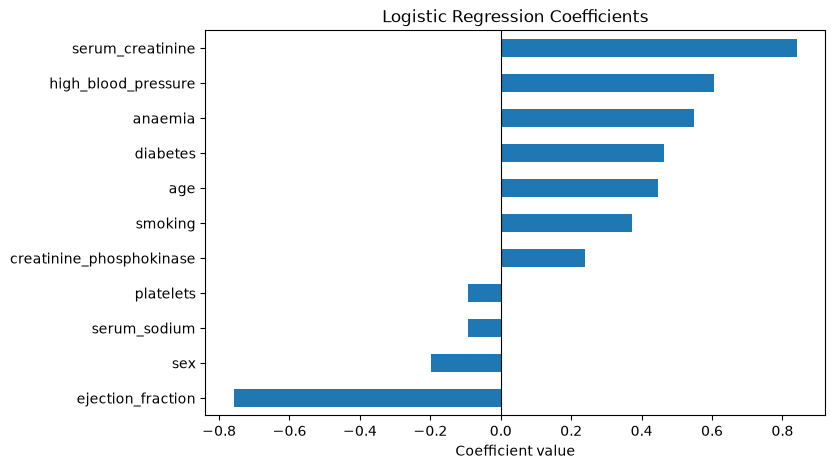

In [4]:

feature_names = cont_cols + [c for c in X.columns if c not in cont_cols]

coefs = pd.Series(
    lr.named_steps['model'].coef_[0],
    index=feature_names
).sort_values()

coefs.plot.barh(figsize=(8, 5))
plt.axvline(0, color='black', lw=0.8)
plt.title('Logistic Regression Coefficients')
plt.xlabel('Coefficient value')
plt.show()


In [5]:

lda = make_pipeline(LinearDiscriminantAnalysis())
lda.fit(X_train, y_train)

lda_pred = lda.predict(X_test)
lda_proba = lda.predict_proba(X_test)[:, 1]

print("LDA trained successfully!")
print("Predicted death events:", int(lda_pred.sum()))

qda = make_pipeline(QuadraticDiscriminantAnalysis())
qda.fit(X_train, y_train)

qda_pred = qda.predict(X_test)
qda_proba = qda.predict_proba(X_test)[:, 1]

print("QDA trained successfully!")
print("Predicted death events:", int(qda_pred.sum()))


LDA trained successfully!
Predicted death events: 14
QDA trained successfully!
Predicted death events: 15


In [6]:

models = {
    'Logistic Regression': (lr_pred, lr_proba),
    'LDA': (lda_pred, lda_proba),
    'QDA': (qda_pred, qda_proba)
}

rows = []

for name, (pred, proba) in models.items():
    rows.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0),
        roc_auc_score(y_test, proba)
    ])

results = pd.DataFrame(
    rows,
    columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
).set_index('Model')

results.round(3)


,Accuracy,Precision,Recall,F1,AUC
Model,,,,,
Logistic Regression,0.717,0.571,0.421,0.485,0.743
LDA,0.717,0.571,0.421,0.485,0.727
QDA,0.700,0.533,0.421,0.471,0.677


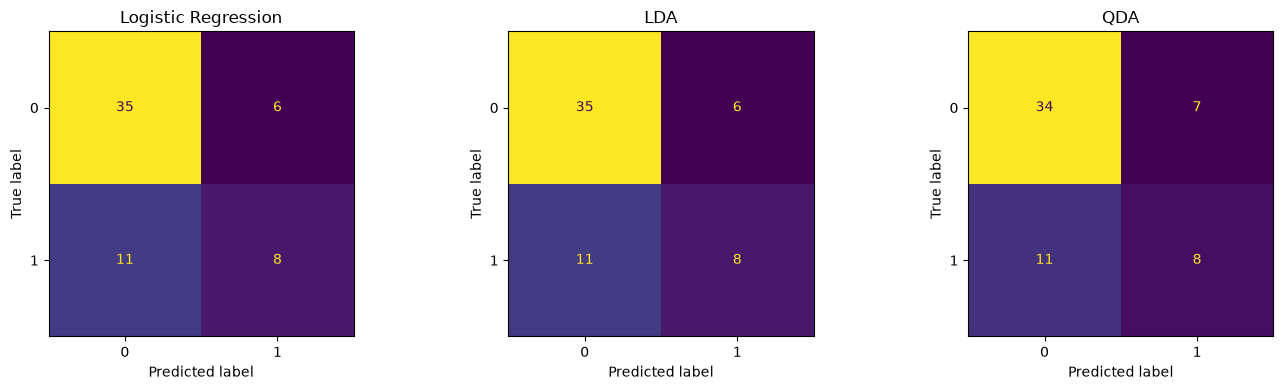

In [7]:

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, (pred, _)) in zip(axes, models.items()):
    ConfusionMatrixDisplay(
        confusion_matrix(y_test, pred)
    ).plot(ax=ax, colorbar=False)

    ax.set_title(name)

plt.tight_layout()
plt.show()


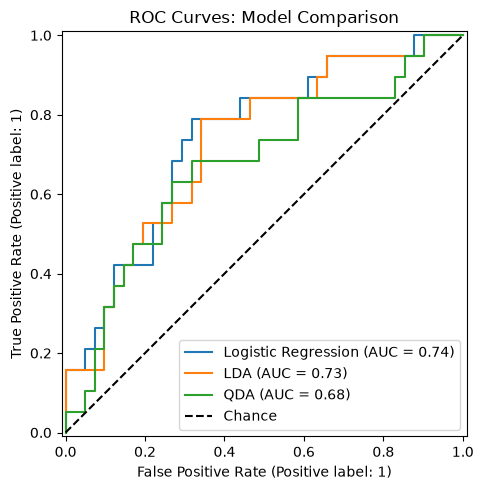

In [8]:

fig, ax = plt.subplots(figsize=(7, 5))

for name, (_, proba) in models.items():
    RocCurveDisplay.from_predictions(
        y_test, proba, name=name, ax=ax
    )

ax.plot([0, 1], [0, 1], 'k--', label='Chance')
ax.set_title('ROC Curves: Model Comparison')
ax.legend()
plt.tight_layout()
plt.show()


In [9]:

results.to_csv('../report/baseline_results.csv')

print("Results saved successfully!")
print(results.round(3))


Results saved successfully!
                     Accuracy  Precision  Recall     F1    AUC
Model                                                         
Logistic Regression     0.717      0.571   0.421  0.485  0.743
LDA                     0.717      0.571   0.421  0.485  0.727
QDA                     0.700      0.533   0.421  0.471  0.677
